In [1]:
import os
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from transformers import AutoTokenizer

print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu128
CUDA: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


In [2]:
DATA_PATH = "../data/processed/m_absa_selected.csv"

df = pd.read_csv(DATA_PATH)

print("Rows:", len(df))
print("Reviews:", df["text"].nunique())
print("Languages:", sorted(df["language"].unique()))
print("Domains:", sorted(df["domain"].unique()))

Rows: 27582
Reviews: 17795
Languages: ['de', 'en', 'ru']
Domains: ['hotel', 'laptop', 'restaurant']


In [3]:
sentiment_labels = sorted(df["sentiment"].unique())
category_labels = sorted(df["category"].unique())

sentiment2id = {
    label: idx
    for idx, label in enumerate(sentiment_labels)
}

id2sentiment = {
    idx: label
    for label, idx in sentiment2id.items()
}

category2id = {
    label: idx
    for idx, label in enumerate(category_labels)
}

id2category = {
    idx: label
    for label, idx in category2id.items()
}

df["sentiment_label"] = df["sentiment"].map(sentiment2id)
df["category_label"] = df["category"].map(category2id)

print("Sentiment:", sentiment2id)
print("Number of categories:", len(category_labels))

Sentiment: {'negative': 0, 'neutral': 1, 'positive': 2}
Number of categories: 153


In [4]:
from transformers import AutoModel
import torch.nn as nn


class MultiTaskXLMR(nn.Module):
    def __init__(
        self,
        model_name,
        num_sentiment_classes,
        num_category_classes,
        dropout=0.1
    ):
        super().__init__()

        self.encoder = AutoModel.from_pretrained(model_name)

        hidden_size = self.encoder.config.hidden_size

        self.dropout = nn.Dropout(dropout)

        self.sentiment_classifier = nn.Linear(
            hidden_size,
            num_sentiment_classes
        )

        self.category_classifier = nn.Linear(
            hidden_size,
            num_category_classes
        )

    def forward(self, input_ids, attention_mask):
        outputs = self.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        pooled_output = outputs.last_hidden_state[:, 0, :]
        pooled_output = self.dropout(pooled_output)

        sentiment_logits = self.sentiment_classifier(
            pooled_output
        )

        category_logits = self.category_classifier(
            pooled_output
        )

        return {
            "sentiment_logits": sentiment_logits,
            "category_logits": category_logits
        }

In [5]:
MODEL_DIR = "../models/absa/xlmr_multitask"

MODEL_NAME = "xlm-roberta-base"

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = MultiTaskXLMR(
    model_name=MODEL_NAME,
    num_sentiment_classes=len(sentiment_labels),
    num_category_classes=len(category_labels)
)

state_dict = torch.load(
    f"{MODEL_DIR}/model.pt",
    map_location=device
)

model.load_state_dict(state_dict)

model = model.to(device)
model.eval()

tokenizer = AutoTokenizer.from_pretrained(MODEL_DIR)

print("Model loaded")
print("Device:", device)

Model loaded
Device: cuda


In [6]:
MAX_LENGTH = 128


def predict_batch(texts, aspects):
    encoded = tokenizer(
        texts,
        aspects,
        truncation=True,
        max_length=MAX_LENGTH,
        padding=True,
        return_tensors="pt"
    )

    encoded = {
        key: value.to(device)
        for key, value in encoded.items()
    }

    with torch.no_grad():
        outputs = model(**encoded)

    sentiment_preds = torch.argmax(
        outputs["sentiment_logits"],
        dim=1
    ).cpu().numpy()

    category_preds = torch.argmax(
        outputs["category_logits"],
        dim=1
    ).cpu().numpy()

    return sentiment_preds, category_preds

In [7]:
sample = df.sample(10, random_state=42).reset_index(drop=True)

sentiment_preds, category_preds = predict_batch(
    sample["text"].tolist(),
    sample["aspect"].fillna("NULL").tolist()
)

sample["predicted_sentiment"] = [
    id2sentiment[x]
    for x in sentiment_preds
]

sample["predicted_category"] = [
    id2category[x]
    for x in category_preds
]

sample[
    [
        "text",
        "aspect",
        "sentiment",
        "predicted_sentiment",
        "category",
        "predicted_category",
        "language",
        "domain"
    ]
]

,text,aspect,sentiment,predicted_sentiment,category,predicted_category,language,domain
0,der Laptop war bei der Ankunft kaputt.,Laptop,negative,negative,LAPTOP#GENERAL,LAPTOP#QUALITY,de,laptop
1,zum beispiel funktioniert die android youtube ...,android youtube app,negative,negative,SOFTWARE#OPERATION_PERFORMANCE,SOFTWARE#OPERATION_PERFORMANCE,de,laptop
2,+ comfortable keyboard,keyboard,positive,positive,KEYBOARD#DESIGN_FEATURES,KEYBOARD#GENERAL,en,laptop
3,Habe die Trainingseinrichtungen nicht oft genu...,Trainingseinrichtungen,positive,positive,facilities general,facilities general,de,hotel
4,trackbad : it could be better but it ' s not b...,trackbad,positive,positive,KEYBOARD#GENERAL,KEYBOARD#GENERAL,en,laptop
5,"However , I think Jeckll and Hydes t is one of...",Jeckll and Hydes,positive,positive,restaurant general,restaurant general,en,restaurant
6,"Server machte mehrere sake Vorschläge, die seh...",sake,positive,positive,drinks quality,drinks quality,de,restaurant
7,Вы не будете разочарованы. Очень хороший 4-зве...,отель,positive,positive,hotel quality,hotel general,ru,hotel
8,"Wonderful Hotel , wonderful country , wonderfu...",Hotel,positive,positive,hotel general,hotel general,en,hotel
9,"Das Essen im Drehrestaurant war ausgezeichnet,...",Service,positive,negative,service general,service general,de,hotel


In [8]:
BATCH_SIZE = 32

test_df = df[df["split"] == "test"].copy().reset_index(drop=True)

all_sentiment_preds = []
all_category_preds = []

for start in range(0, len(test_df), BATCH_SIZE):
    batch_df = test_df.iloc[start:start + BATCH_SIZE]

    sentiment_preds, category_preds = predict_batch(
        batch_df["text"].tolist(),
        batch_df["aspect"].fillna("NULL").tolist()
    )

    all_sentiment_preds.extend(sentiment_preds)
    all_category_preds.extend(category_preds)

    if (start // BATCH_SIZE + 1) % 20 == 0:
        print(f"Processed: {min(start + BATCH_SIZE, len(test_df))}/{len(test_df)}")

test_df["predicted_sentiment"] = [
    id2sentiment[x] for x in all_sentiment_preds
]

test_df["predicted_category"] = [
    id2category[x] for x in all_category_preds
]

print("Done:", len(test_df))

Done: 7611


In [9]:
sentiment_precision, sentiment_recall, sentiment_f1, _ = (
    precision_recall_fscore_support(
        test_df["sentiment"],
        test_df["predicted_sentiment"],
        average="macro",
        zero_division=0
    )
)

sentiment_accuracy = accuracy_score(
    test_df["sentiment"],
    test_df["predicted_sentiment"]
)

category_precision, category_recall, category_f1, _ = (
    precision_recall_fscore_support(
        test_df["category"],
        test_df["predicted_category"],
        average="macro",
        zero_division=0
    )
)

category_accuracy = accuracy_score(
    test_df["category"],
    test_df["predicted_category"]
)

overall_metrics = pd.DataFrame([{
    "sentiment_accuracy": sentiment_accuracy,
    "sentiment_precision_macro": sentiment_precision,
    "sentiment_recall_macro": sentiment_recall,
    "sentiment_f1_macro": sentiment_f1,
    "category_accuracy": category_accuracy,
    "category_precision_macro": category_precision,
    "category_recall_macro": category_recall,
    "category_f1_macro": category_f1
}])

overall_metrics

,sentiment_accuracy,sentiment_precision_macro,sentiment_recall_macro,sentiment_f1_macro,category_accuracy,category_precision_macro,category_recall_macro,category_f1_macro
0,0.901196,0.659278,0.607518,0.604541,0.621863,0.178897,0.195158,0.17286


In [10]:
language_results = []

for language in sorted(test_df["language"].unique()):
    subset = test_df[test_df["language"] == language]

    precision, recall, f1, _ = precision_recall_fscore_support(
        subset["sentiment"],
        subset["predicted_sentiment"],
        average="macro",
        zero_division=0
    )

    accuracy = accuracy_score(
        subset["sentiment"],
        subset["predicted_sentiment"]
    )

    language_results.append({
        "language": language,
        "samples": len(subset),
        "accuracy": accuracy,
        "precision_macro": precision,
        "recall_macro": recall,
        "f1_macro": f1
    })

language_results = pd.DataFrame(language_results)

language_results

,language,samples,accuracy,precision_macro,recall_macro,f1_macro
0,de,2533,0.901698,0.660237,0.609297,0.608855
1,en,2537,0.900276,0.616081,0.603288,0.595389
2,ru,2541,0.901614,0.707219,0.609992,0.609336


In [11]:
sentiment_report = classification_report(
    test_df["sentiment"],
    test_df["predicted_sentiment"],
    labels=["negative", "neutral", "positive"],
    output_dict=True,
    zero_division=0
)

sentiment_report_df = pd.DataFrame(sentiment_report).T

sentiment_report_df

,precision,recall,f1-score,support
negative,0.815275,0.830519,0.822826,1658.000000
neutral,0.233333,0.023179,0.042169,302.000000
positive,0.929226,0.968855,0.948627,5651.000000
accuracy,0.901196,0.901196,0.901196,0.901196
macro avg,0.659278,0.607518,0.604541,7611.000000
weighted avg,0.876790,0.901196,0.885254,7611.000000


In [12]:
cm = confusion_matrix(
    test_df["sentiment"],
    test_df["predicted_sentiment"],
    labels=["negative", "neutral", "positive"]
)

cm_df = pd.DataFrame(
    cm,
    index=["actual_negative", "actual_neutral", "actual_positive"],
    columns=["pred_negative", "pred_neutral", "pred_positive"]
)

cm_df

,pred_negative,pred_neutral,pred_positive
actual_negative,1377,17,264
actual_neutral,142,7,153
actual_positive,170,6,5475


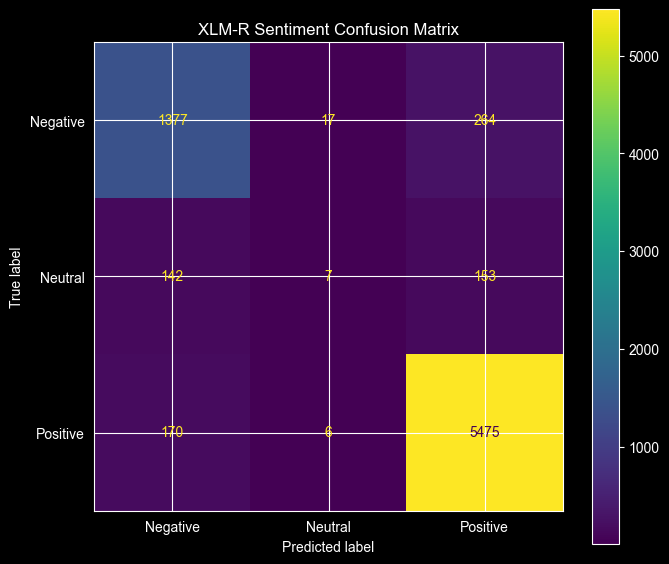

In [13]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Neutral", "Positive"]
)

disp.plot(
    ax=ax,
    values_format="d"
)

ax.set_title("XLM-R Sentiment Confusion Matrix")
plt.tight_layout()
plt.show()

In [14]:
cm_df.to_csv(
    "../data/processed/transformer_sentiment_confusion_matrix.csv"
)

print("Confusion matrix saved.")

Confusion matrix saved.


In [15]:
neutral_by_language = []

for language in sorted(test_df["language"].unique()):
    subset = test_df[
        (test_df["language"] == language) &
        (test_df["sentiment"] == "neutral")
    ]

    precision, recall, f1, _ = precision_recall_fscore_support(
        subset["sentiment"],
        subset["predicted_sentiment"],
        labels=["neutral"],
        average="macro",
        zero_division=0
    )

    neutral_by_language.append({
        "language": language,
        "neutral_samples": len(subset),
        "neutral_precision": precision,
        "neutral_recall": recall,
        "neutral_f1": f1
    })

neutral_by_language = pd.DataFrame(neutral_by_language)

neutral_by_language

,language,neutral_samples,neutral_precision,neutral_recall,neutral_f1
0,de,100,1.0,0.030000,0.058252
1,en,101,1.0,0.009901,0.019608
2,ru,101,1.0,0.029703,0.057692


In [16]:
language_class_results = []

for language in sorted(test_df["language"].unique()):
    subset = test_df[test_df["language"] == language]

    report = classification_report(
        subset["sentiment"],
        subset["predicted_sentiment"],
        labels=["negative", "neutral", "positive"],
        output_dict=True,
        zero_division=0
    )

    for sentiment in ["negative", "neutral", "positive"]:
        language_class_results.append({
            "language": language,
            "sentiment": sentiment,
            "precision": report[sentiment]["precision"],
            "recall": report[sentiment]["recall"],
            "f1": report[sentiment]["f1-score"],
            "support": report[sentiment]["support"]
        })

language_class_results = pd.DataFrame(language_class_results)

language_class_results

,language,sentiment,precision,recall,f1,support
0,de,negative,0.820789,0.828210,0.824482,553.0
1,de,neutral,0.230769,0.030000,0.053097,100.0
2,de,positive,0.929154,0.969681,0.948985,1880.0
3,en,negative,0.805604,0.831826,0.818505,553.0
4,en,neutral,0.111111,0.009901,0.018182,101.0
5,en,positive,0.931528,0.968136,0.949479,1883.0
6,ru,negative,0.819643,0.831522,0.825540,552.0
7,ru,neutral,0.375000,0.029703,0.055046,101.0
8,ru,positive,0.927015,0.968750,0.947423,1888.0


In [17]:
language_domain_results = []

for language in sorted(test_df["language"].unique()):
    for domain in sorted(test_df["domain"].unique()):

        subset = test_df[
            (test_df["language"] == language) &
            (test_df["domain"] == domain)
        ]

        precision, recall, f1, _ = precision_recall_fscore_support(
            subset["sentiment"],
            subset["predicted_sentiment"],
            average="macro",
            zero_division=0
        )

        accuracy = accuracy_score(
            subset["sentiment"],
            subset["predicted_sentiment"]
        )

        language_domain_results.append({
            "language": language,
            "domain": domain,
            "samples": len(subset),
            "accuracy": accuracy,
            "precision_macro": precision,
            "recall_macro": recall,
            "f1_macro": f1
        })

language_domain_results = pd.DataFrame(
    language_domain_results
)

language_domain_results

,language,domain,samples,accuracy,precision_macro,recall_macro,f1_macro
0,de,hotel,978,0.934560,0.584564,0.586985,0.585684
1,de,laptop,759,0.877470,0.664605,0.629439,0.632724
2,de,restaurant,796,0.884422,0.566226,0.595333,0.580415
3,en,hotel,977,0.938588,0.590500,0.592835,0.591576
4,en,laptop,758,0.869393,0.614950,0.611360,0.603458
5,en,restaurant,802,0.882793,0.561508,0.593546,0.577070
6,ru,hotel,982,0.939919,0.601576,0.589022,0.594690
7,ru,laptop,761,0.864652,0.717029,0.619292,0.624670
8,ru,restaurant,798,0.889724,0.567130,0.606683,0.586029


In [19]:
language_domain_pivot = language_domain_results.pivot(
    index="language",
    columns="domain",
    values="f1_macro"
)

language_domain_pivot

domain,hotel,laptop,restaurant
language,,,
de,0.585684,0.632724,0.580415
en,0.591576,0.603458,0.577070
ru,0.594690,0.624670,0.586029


In [20]:
language_domain_results.to_csv(
    "../data/processed/transformer_by_language_domain.csv",
    index=False
)

language_domain_pivot.to_csv(
    "../data/processed/transformer_language_domain_f1.csv"
)

print("Language × Domain analysis saved.")

Language × Domain analysis saved.


In [21]:
errors = test_df[
    test_df["sentiment"] != test_df["predicted_sentiment"]
].copy()

print("Total test samples:", len(test_df))
print("Sentiment errors:", len(errors))
print(
    "Error rate:",
    round(len(errors) / len(test_df) * 100, 2),
    "%"
)

Total test samples: 7611
Sentiment errors: 752
Error rate: 9.88 %


In [22]:
error_pairs = (
    errors
    .groupby(["sentiment", "predicted_sentiment"])
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

error_pairs

,sentiment,predicted_sentiment,count
1,negative,positive,264
4,positive,negative,170
3,neutral,positive,153
2,neutral,negative,142
0,negative,neutral,17
5,positive,neutral,6


In [23]:
neutral_to_positive = test_df[
    (test_df["sentiment"] == "neutral") &
    (test_df["predicted_sentiment"] == "positive")
][[
    "text",
    "aspect",
    "category",
    "language",
    "domain",
    "predicted_sentiment",
    "predicted_category"
]]

neutral_to_positive.head(20)

,text,aspect,category,language,domain,predicted_sentiment,predicted_category
41,It is n't the cheapest sushi but has been wort...,sushi,food prices,en,restaurant,positive,food quality
119,– I decided to eat at Stack because of their p...,price fixed pre-show dinner,food prices,en,restaurant,positive,food prices
127,Fair menu selection .,menu selection,food style_options,en,restaurant,positive,food quality
146,It was decent but nothing exceptional .,NaN,food quality,en,restaurant,positive,food quality
176,– tucked away over by the Beverly Center .,NaN,location general,en,restaurant,positive,location general
195,– Not bad .,NaN,restaurant general,en,restaurant,positive,restaurant general
198,Waited 35 minutes for a table for 8 which was ...,NaN,service general,en,restaurant,positive,restaurant miscellaneous
356,It was so much though that I could barely fini...,NaN,food style_options,en,restaurant,positive,food quality
372,Our server continued to be attentive throughou...,Ray 's,restaurant miscellaneous,en,restaurant,positive,restaurant general
375,"Good Food , Great Service , Average Prices ( F...",NaN,restaurant prices,en,restaurant,positive,hotel prices


In [24]:
neutral_to_negative = test_df[
    (test_df["sentiment"] == "neutral") &
    (test_df["predicted_sentiment"] == "negative")
][[
    "text",
    "aspect",
    "category",
    "language",
    "domain",
    "predicted_sentiment",
    "predicted_category"
]]

neutral_to_negative.head(20)

,text,aspect,category,language,domain,predicted_sentiment,predicted_category
52,The outside patio area has an abbreviated menu .,menu,food style_options,en,restaurant,negative,food style_options
214,"Food wise , its ok but a bit pricey for what y...",Food,food quality,en,restaurant,negative,food quality
216,"Food wise , its ok but a bit pricey for what y...",restaurant,ambience general,en,restaurant,negative,restaurant prices
226,"It was n't the freshest seafood ever , but the...",seafood,food style_options,en,restaurant,negative,food quality
227,"It was n't the freshest seafood ever , but the...",seafood,food quality,en,restaurant,negative,food quality
228,"It was n't the freshest seafood ever , but the...",seafood,food quality,en,restaurant,negative,food quality
286,"Portions was just enough for me , but may not ...",Portions,food style_options,en,restaurant,negative,food style_options
326,Not the biggest portions but adequate .,portions,food style_options,en,restaurant,negative,food style_options
423,It 's a tiny place so if you get there before ...,place,restaurant miscellaneous,en,restaurant,negative,restaurant miscellaneous
481,– Schooner or Later 's charming location along...,food,food quality,en,restaurant,negative,food quality


In [25]:
category_errors = test_df[
    test_df["category"] != test_df["predicted_category"]
].copy()

print("Category errors:", len(category_errors))
print(
    "Category error rate:",
    round(len(category_errors) / len(test_df) * 100, 2),
    "%"
)

Category errors: 2878
Category error rate: 37.81 %


In [26]:
category_error_pairs = (
    category_errors
    .groupby(["category", "predicted_category"])
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

category_error_pairs.head(30)

,category,predicted_category,count
332,food style_options,food quality,90
382,hotel general,restaurant general,73
474,rooms cleanliness,rooms design_features,68
494,rooms general,rooms design_features,56
135,LAPTOP#GENERAL,LAPTOP#OPERATION_PERFORMANCE,54
316,food prices,food quality,41
402,location general,hotel general,40
381,hotel general,location general,38
482,rooms comfort,rooms design_features,37
1,BATTERY#GENERAL,BATTERY#OPERATION_PERFORMANCE,37


In [27]:
category_errors[[
    "text",
    "aspect",
    "category",
    "predicted_category",
    "sentiment",
    "predicted_sentiment",
    "language",
    "domain"
]].head(30)

,text,aspect,category,predicted_category,sentiment,predicted_sentiment,language,domain
2,Fantastic !,NaN,restaurant general,hotel general,positive,positive,en,restaurant
5,hidden little jem,NaN,restaurant general,ambience general,positive,negative,en,restaurant
9,"All their menu items are a hit , and they serv...",menu items,food quality,food style_options,positive,positive,en,restaurant
15,– The pepperoni 's cut real thick -- Yum .,pepperoni 's,food style_options,food quality,positive,positive,en,restaurant
19,absolutely fabulous ! ! !,NaN,restaurant general,hotel general,positive,positive,en,restaurant
27,"To start off , approximately 8-10 oz of orange...",orange juice,drinks prices,food prices,negative,negative,en,restaurant
31,While I could have done without the youth who ...,NaN,restaurant miscellaneous,restaurant general,positive,positive,en,restaurant
34,– Mioposto has a very creative & delicious piz...,pizza menu,food style_options,food quality,positive,positive,en,restaurant
41,It is n't the cheapest sushi but has been wort...,sushi,food prices,food quality,neutral,positive,en,restaurant
43,You never feel icky and stuffed after you eat ...,NaN,food quality,restaurant general,positive,positive,en,restaurant


In [28]:
errors.to_csv(
    "../data/processed/sentiment_errors.csv",
    index=False,
    encoding="utf-8"
)

error_pairs.to_csv(
    "../data/processed/sentiment_error_pairs.csv",
    index=False,
    encoding="utf-8"
)

category_errors.to_csv(
    "../data/processed/category_errors.csv",
    index=False,
    encoding="utf-8"
)

category_error_pairs.to_csv(
    "../data/processed/category_error_pairs.csv",
    index=False,
    encoding="utf-8"
)

print("Error analysis saved.")

Error analysis saved.


In [29]:
evaluation_summary = pd.DataFrame([
    {
        "task": "Sentiment",
        "accuracy": sentiment_accuracy,
        "precision_macro": sentiment_precision,
        "recall_macro": sentiment_recall,
        "f1_macro": sentiment_f1
    },
    {
        "task": "Category",
        "accuracy": category_accuracy,
        "precision_macro": category_precision,
        "recall_macro": category_recall,
        "f1_macro": category_f1
    }
])

evaluation_summary

,task,accuracy,precision_macro,recall_macro,f1_macro
0,Sentiment,0.901196,0.659278,0.607518,0.604541
1,Category,0.621863,0.178897,0.195158,0.172860


In [30]:
evaluation_summary.to_csv(
    "../data/processed/transformer_evaluation_summary.csv",
    index=False
)